In [25]:
import numpy as np
import matplotlib.pyplot as plt

# Logistic Regression Without Any Library

In [29]:
def visualize_data_with_decision_boundary(X, y, theta=None, model=None):
    # Separate the points based on their label
    X0 = X[y == 0]
    X1 = X[y == 1]
    
    # Create the plot
    plt.figure(figsize=(8, 6))
    plt.scatter(X0[:, 0], X0[:, 1], color='red', label='Class 0', edgecolor='k', s=100)
    plt.scatter(X1[:, 0], X1[:, 1], color='blue', label='Class 1', edgecolor='k', s=100)
    
    # Plot decision boundary if theta or model is provided
    if theta is not None or model is not None:
        # Create a mesh grid
        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))
        
        # Calculate the decision boundary
        if theta is not None:
            Z = sigmoid(np.c_[np.ones((xx.ravel().shape[0], 1)), xx.ravel(), yy.ravel()].dot(theta))
        elif model is not None:
            Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
        
        Z = Z.reshape(xx.shape)
        
        # Plot decision boundary
        plt.contourf(xx, yy, Z, levels=[0, 0.5, 1], alpha=0.2, colors=['red', 'blue'])

    # Adding labels and title
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.title('Toy Problem Data with Decision Boundary')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example Usage:

# For manual implementation (using theta)
# visualize_data_with_decision_boundary(X, y, theta=theta)

# For sklearn implementation (using model)
# visualize_data_with_decision_boundary(X, y, model=model)

In [31]:
# Sample data (toy problem)
X = np.array([[0.5, 1.5], [1.5, 2.0], [1.0, 1.0], [2.0, 2.5], [3.0, 3.0], [2.5, 3.5], [3.5, 4.0], [4.0, 4.5]])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])  # Binary labels

In [15]:
# Sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Logistic regression using gradient descent
def logistic_regression(X, y, learning_rate=0.1, num_iterations=1000):
    m, n = X.shape
    X = np.c_[np.ones((m, 1)), X]  # Add intercept term
    theta = np.zeros(n + 1)  # Initialize parameters
    
    for _ in range(num_iterations):
        z = np.dot(X, theta)
        h = sigmoid(z)
        gradient = np.dot(X.T, (h - y)) / m
        theta -= learning_rate * gradient
    
    return theta

# Train the model
theta = logistic_regression(X, y)



# Prediction function
def predict(X, theta, detailed=False):
    X = np.c_[np.ones((X.shape[0], 1)), X]  # Add intercept term
    a = np.dot(X, theta)
    if detailed:
        return np.array(list(zip(sigmoid(np.dot(X, theta)) >= 0.5, sigmoid(np.dot(X, theta)), np.dot(X, theta))))
    return sigmoid(np.dot(X, theta)) >= 0.5

# Predictions
predictions = predict(X, theta, detailed=True)
print("Manual Logistic Regression Predictions:", predictions)


Manual Logistic Regression Predictions: [[ 0.          0.01925355 -3.93061844]
 [ 0.          0.16534348 -1.61899525]
 [ 0.          0.04518481 -3.05075693]
 [ 0.          0.40825102 -0.3712003 ]
 [ 1.          0.87439859  1.94042288]
 [ 1.          0.74279781  1.06056137]
 [ 1.          0.96682383  3.37218456]
 [ 1.          0.99024314  4.61997951]]


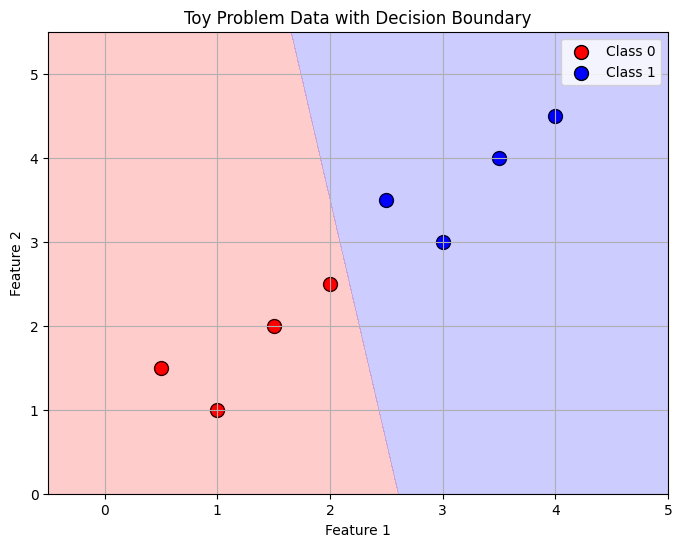

In [32]:
visualize_data_with_decision_boundary(X,y, theta=theta)

# Logistic Regression Using scikit-learn

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Same sample data
X = np.array([[0.5, 1.5], [1.5, 2.0], [1.0, 1.0], [2.0, 2.5], [3.0, 3.0], [2.5, 3.5], [3.5, 4.0], [4.0, 4.5]])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])  # Binary labels

# Train the model
model = LogisticRegression()
model.fit(X, y)

# Predictions
predictions = model.predict(X)
print("sklearn Logistic Regression Predictions:", predictions)


sklearn Logistic Regression Predictions: [0 0 0 0 1 1 1 1]


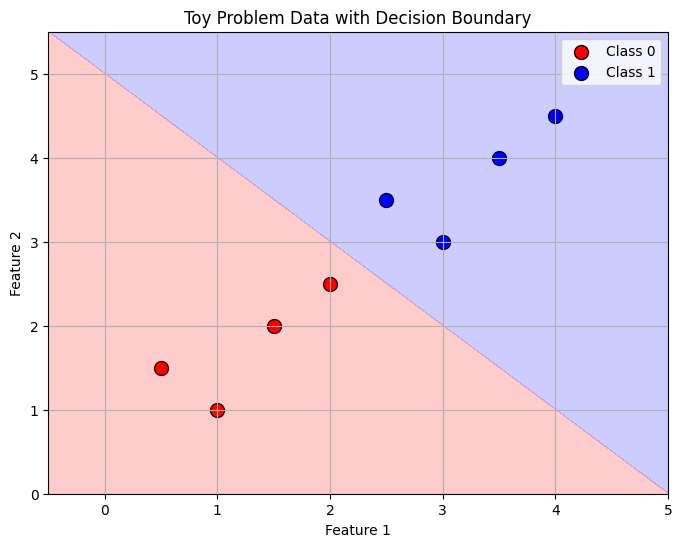

In [33]:
visualize_data_with_decision_boundary(X,y, model=model)